In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")s

Libraries imported successfully!


In [2]:
df = pd.read_csv("viral_songs.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [4]:
print("Rows and columns:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Rows and columns: (10000, 17)
Number of rows: 10000
Number of columns: 17


In [5]:
print(df.columns)
print(df.dtypes)
df.info()

Index(['track_id', 'track_name', 'artist', 'genre', 'release_year',
       'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm',
       'acousticness', 'instrumentalness', 'speechiness', 'liveness',
       'loudness_db', 'streams', 'viral'],
      dtype='str')
track_id                str
track_name              str
artist                  str
genre                   str
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  str    

In [6]:
print(df.isnull().sum())

track_id            0
track_name          0
artist              0
genre               0
release_year        0
duration_sec        0
danceability        0
energy              0
valence             0
tempo_bpm           0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
loudness_db         0
streams             0
viral               0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [8]:
print(df["viral"].value_counts())
print("\nProportion of each class:")
print(df["viral"].value_counts(normalize=True) * 100)

viral
0    6395
1    3605
Name: count, dtype: int64

Proportion of each class:
viral
0    63.95
1    36.05
Name: proportion, dtype: float64


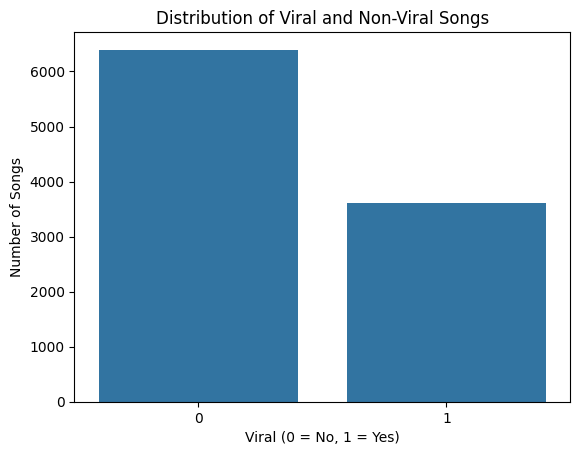

In [9]:
sns.countplot(data=df, x="viral")

plt.title("Distribution of Viral and Non-Viral Songs")
plt.xlabel("Viral (0 = No, 1 = Yes)")
plt.ylabel("Number of Songs")
plt.show()

In [10]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
track_id            0
track_name          0
artist              0
genre               0
release_year        0
duration_sec        0
danceability        0
energy              0
valence             0
tempo_bpm           0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
loudness_db         0
streams             0
viral               0
dtype: int64

Total missing values: 0


In [11]:
# Check completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate song IDs
print("Duplicate track IDs:", df["track_id"].duplicated().sum())

Duplicate rows: 0
Duplicate track IDs: 0


In [12]:
print("Duplicate song titles:", df["track_name"].duplicated().sum())

Duplicate song titles: 0


In [14]:
audio_features = [
    "danceability",
    "energy",
    "valence",
    "acousticness",
    "instrumentalness",
    "speechiness",
    "liveness"
]

for column in audio_features:
    invalid = ((df[column] < 0) | (df[column] > 1)).sum()
    print(column, "- invalid values:", invalid)

danceability - invalid values: 0
energy - invalid values: 0
valence - invalid values: 0
acousticness - invalid values: 0
instrumentalness - invalid values: 0
speechiness - invalid values: 0
liveness - invalid values: 0


In [15]:
print("Release year range:",
      df["release_year"].min(), "to", df["release_year"].max())

print("Song duration range:",
      df["duration_sec"].min(), "to", df["duration_sec"].max())

print("Minimum streams:", df["streams"].min())
print("Maximum streams:", df["streams"].max())

print("Viral labels:", sorted(df["viral"].unique()))

Release year range: 2010 to 2025
Song duration range: 60 to 433
Minimum streams: 134
Maximum streams: 443068342
Viral labels: [np.int64(0), np.int64(1)]


In [16]:
text_columns = ["track_id", "track_name", "artist", "genre"]

for column in text_columns:
    print(
        column,
        "- values with extra spaces:",
        (df[column] != df[column].str.strip()).sum()
    )

track_id - values with extra spaces: 0
track_name - values with extra spaces: 0
artist - values with extra spaces: 0
genre - values with extra spaces: 0


In [17]:
for column in text_columns:
    df[column] = df[column].str.strip()

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [18]:
print(df["viral"].value_counts())

viral
0    6395
1    3605
Name: count, dtype: int64


In [19]:
print(df["streams"].describe())

count    1.000000e+04
mean     2.415685e+06
std      9.721026e+06
min      1.340000e+02
25%      8.671450e+04
50%      3.290580e+05
75%      1.343092e+06
max      4.430683e+08
Name: streams, dtype: float64


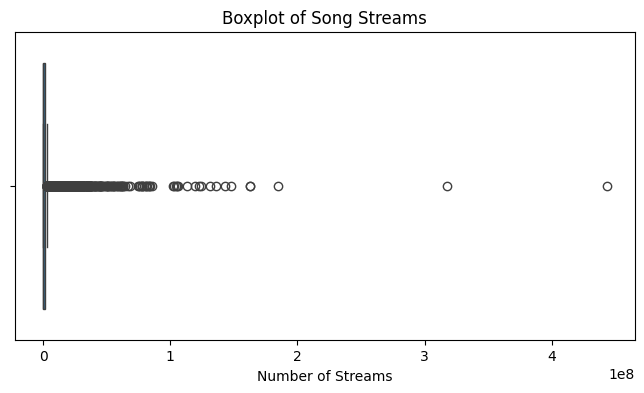

In [20]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["streams"])

plt.title("Boxplot of Song Streams")
plt.xlabel("Number of Streams")
plt.show()

In [21]:
df.to_csv("viral_songs_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [22]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

if os.path.exists("viral_songs_cleaned.csv"):
    df = pd.read_csv("viral_songs_cleaned.csv")
else:
    df = pd.read_csv("viral_songs.csv")

print("Dataset loaded:", df.shape)
df.head()

Dataset loaded: (10000, 17)


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


viral
0    6395
1    3605
Name: count, dtype: int64


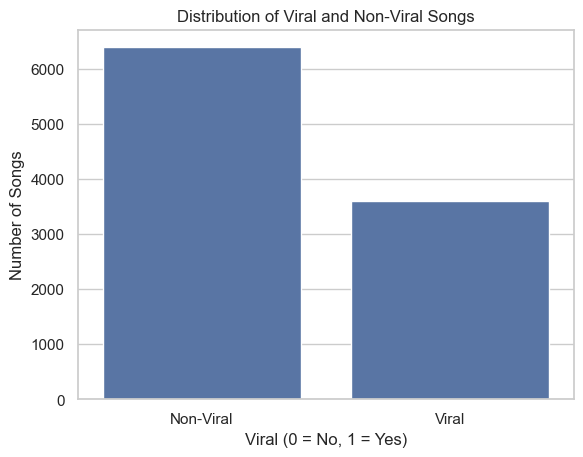

In [23]:
print(df["viral"].value_counts())

sns.countplot(data=df, x="viral")

plt.title("Distribution of Viral and Non-Viral Songs")
plt.xlabel("Viral (0 = No, 1 = Yes)")
plt.ylabel("Number of Songs")
plt.xticks([0, 1], ["Non-Viral", "Viral"])
plt.show()

genre
Latin         64.66
Pop           61.78
Hip-Hop       61.12
Electronic    50.66
R&B           40.53
Rock          32.66
Country       23.89
Indie         13.90
Jazz           6.32
Classical      1.21
Name: viral, dtype: float64


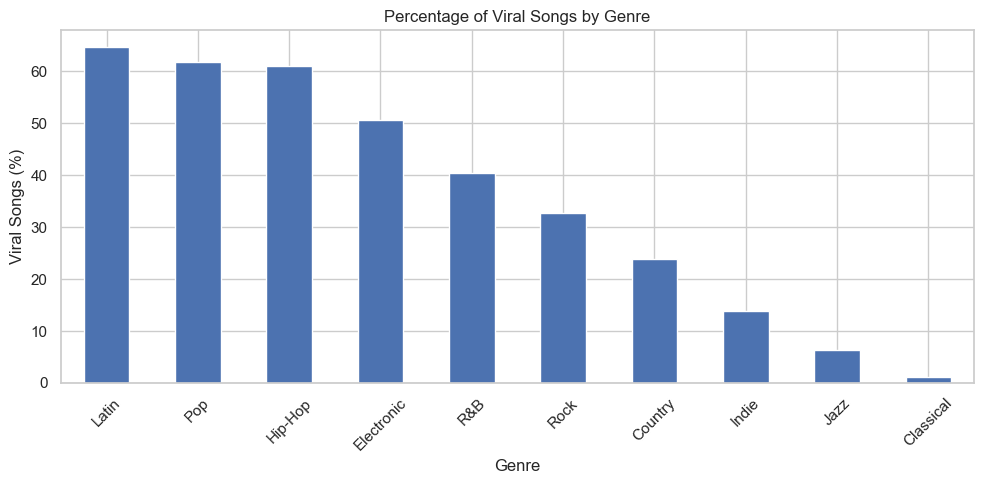

In [24]:
genre_viral_rate = (
    df.groupby("genre")["viral"]
    .mean()
    .sort_values(ascending=False) * 100
)

print(genre_viral_rate.round(2))

genre_viral_rate.plot(kind="bar", figsize=(10, 5))

plt.title("Percentage of Viral Songs by Genre")
plt.xlabel("Genre")
plt.ylabel("Viral Songs (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
features = [
    "danceability",
    "energy",
    "valence",
    "acousticness",
    "instrumentalness",
    "tempo_bpm"
]

print(df.groupby("viral")[features].mean().round(3))

       danceability  energy  valence  acousticness  instrumentalness  \
viral                                                                  
0             0.556   0.609    0.555         0.367             0.186   
1             0.711   0.727    0.631         0.170             0.162   

       tempo_bpm  
viral             
0        110.742  
1        111.391  


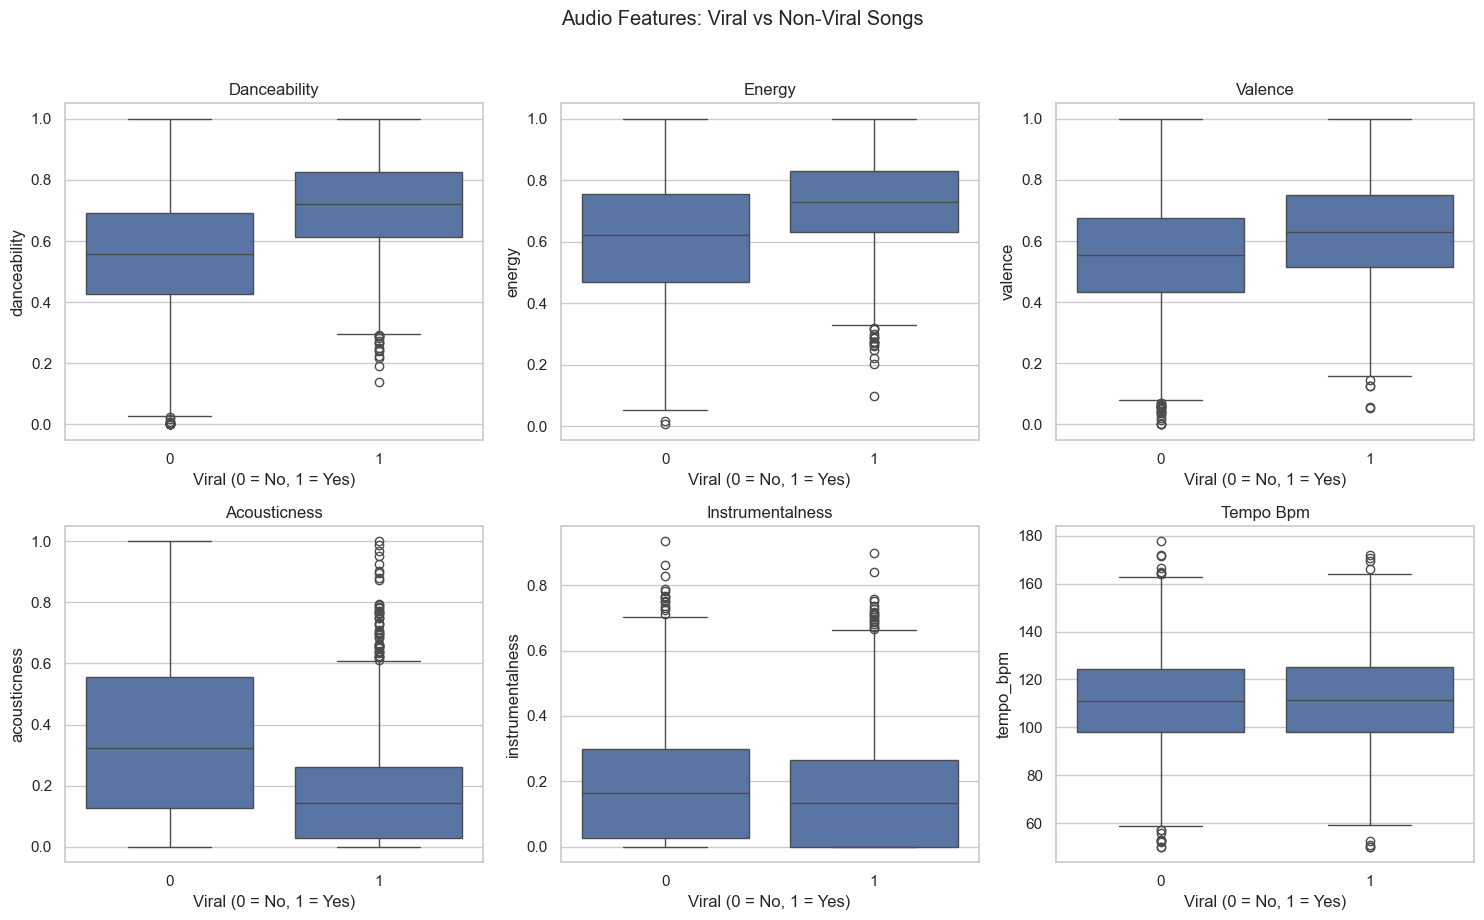

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(
        data=df,
        x="viral",
        y=feature,
        ax=ax
    )
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Viral (0 = No, 1 = Yes)")

plt.suptitle("Audio Features: Viral vs Non-Viral Songs", y=1.02)
plt.tight_layout()
plt.show()

In [27]:
print(df.groupby("viral")["streams"].describe().round(0))

        count       mean         std     min       25%        50%        75%  \
viral                                                                          
0      6395.0   471461.0   1081595.0   134.0   47401.0   149193.0   436244.0   
1      3605.0  5864593.0  15540167.0  8937.0  545278.0  1694602.0  5224834.0   

               max  
viral               
0       19345373.0  
1      443068342.0  


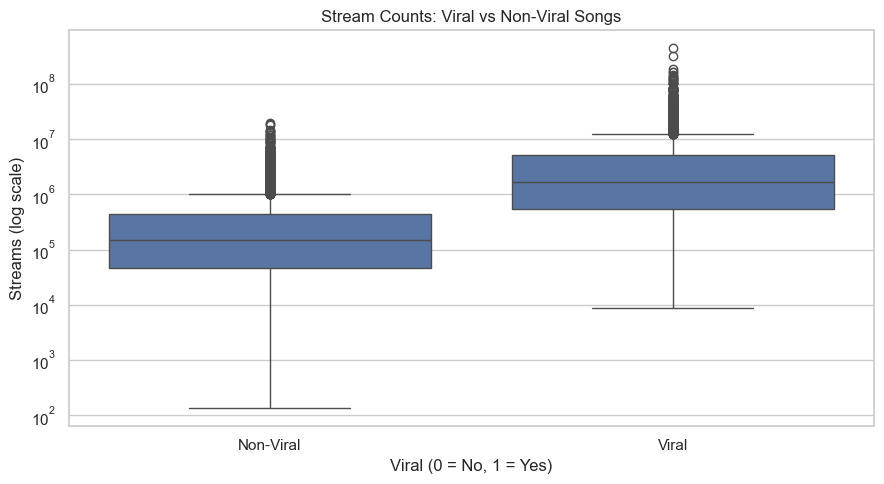

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="viral", y="streams")

plt.yscale("log")
plt.title("Stream Counts: Viral vs Non-Viral Songs")
plt.xlabel("Viral (0 = No, 1 = Yes)")
plt.ylabel("Streams (log scale)")
plt.xticks([0, 1], ["Non-Viral", "Viral"])

plt.tight_layout()
plt.show()

danceability        0.386
energy              0.302
valence             0.205
tempo_bpm           0.016
liveness            0.005
loudness_db        -0.012
speechiness        -0.018
instrumentalness   -0.072
acousticness       -0.359
Name: viral, dtype: float64


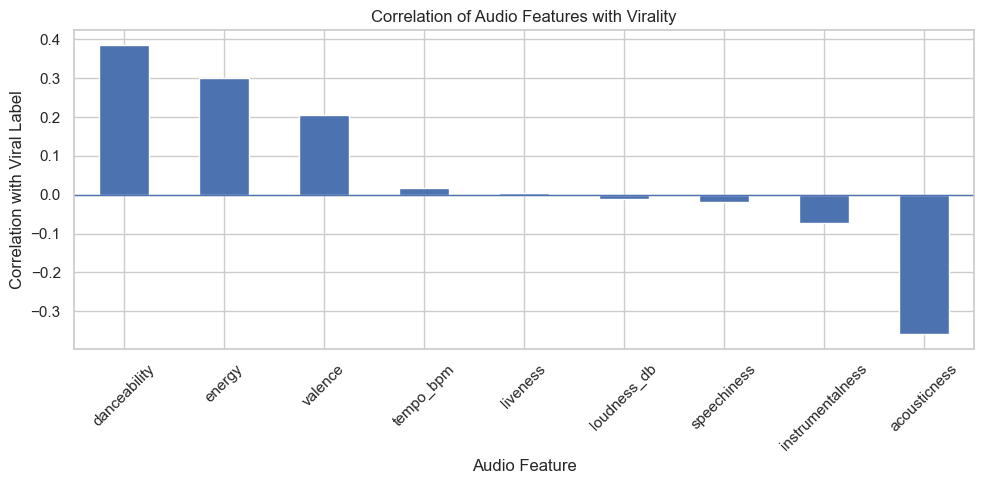

In [29]:
audio_features = [
    "danceability",
    "energy",
    "valence",
    "tempo_bpm",
    "acousticness",
    "instrumentalness",
    "speechiness",
    "liveness",
    "loudness_db"
]

correlations = (
    df[audio_features + ["viral"]]
    .corr(numeric_only=True)["viral"]
    .drop("viral")
    .sort_values(ascending=False)
)

print(correlations.round(3))

correlations.plot(kind="bar", figsize=(10, 5))

plt.title("Correlation of Audio Features with Virality")
plt.xlabel("Audio Feature")
plt.ylabel("Correlation with Viral Label")
plt.axhline(0, linewidth=1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

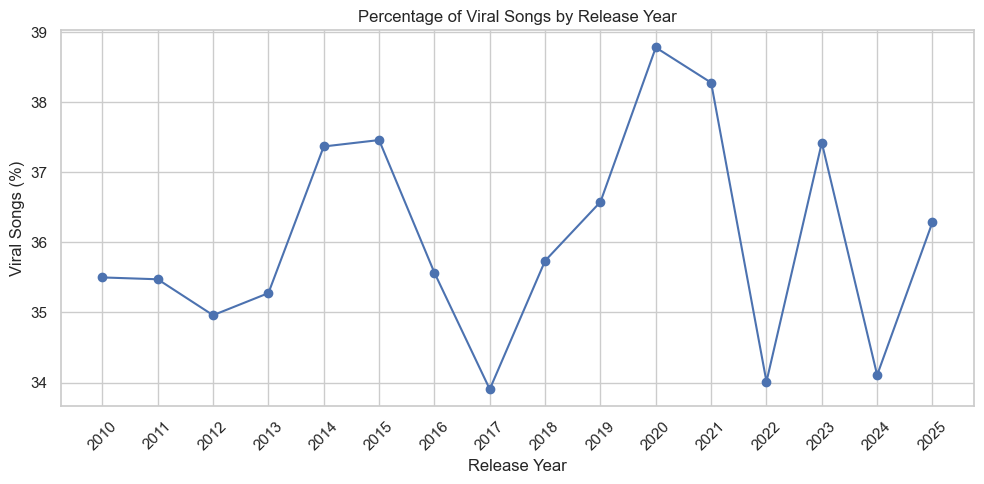

In [30]:
year_viral_rate = (
    df.groupby("release_year")["viral"].mean() * 100
)

plt.figure(figsize=(10, 5))

year_viral_rate.plot(marker="o")

plt.title("Percentage of Viral Songs by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Viral Songs (%)")
plt.xticks(sorted(df["release_year"].unique()), rotation=45)

plt.tight_layout()
plt.show()

In [31]:
print(
    "Correlation between release year and virality:",
    round(df["release_year"].corr(df["viral"]), 3)
)

Correlation between release year and virality: 0.004


In [32]:
import os
import pandas as pd
import numpy as np

if os.path.exists("viral_songs_cleaned.csv"):
    df = pd.read_csv("viral_songs_cleaned.csv")
else:
    df = pd.read_csv("viral_songs.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (10000, 17)
      track_id   track_name       artist       genre  release_year  \
0  track_00001  Track_00001  Artist_1519         Pop          2013   
1  track_00002  Track_00002  Artist_0458  Electronic          2018   
2  track_00003  Track_00003  Artist_1386     Hip-Hop          2014   
3  track_00004  Track_00004  Artist_0865   Classical          2012   
4  track_00005  Track_00005  Artist_0192         Pop          2011   

   duration_sec  danceability  energy  valence  tempo_bpm  acousticness  \
0           237         0.760   0.703    0.747      140.8         0.115   
1           239         0.436   0.934    0.672      105.1         0.016   
2           148         0.642   0.725    0.460       90.6         0.010   
3           216         0.326   0.456    0.299       71.3         0.966   
4           277         0.599   0.683    0.700      132.6         0.078   

   instrumentalness  speechiness  liveness  loudness_db  streams  viral  
0             0.103        

In [33]:
target = "viral"

X = df.drop(columns=[target])
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (10000, 16)
Target shape: (10000,)

Target distribution:
viral
0    6395
1    3605
Name: count, dtype: int64


In [34]:
columns_to_drop = [
    "track_id",
    "track_name",
    "artist",
    "streams"
]

X = df.drop(columns=columns_to_drop + ["viral"])
y = df["viral"]

print("Selected features:")
print(X.columns.tolist())

print("\nNumber of input features:", X.shape[1])

Selected features:
['genre', 'release_year', 'duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness_db']

Number of input features: 12


In [35]:
categorical_features = ["genre"]

numerical_features = [
    "release_year",
    "duration_sec",
    "danceability",
    "energy",
    "valence",
    "tempo_bpm",
    "acousticness",
    "instrumentalness",
    "speechiness",
    "liveness",
    "loudness_db"
]

print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))

Categorical features: ['genre']
Numerical features: 11


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 12)
Testing features: (2000, 12)

Training target distribution:
viral
0    5116
1    2884
Name: count, dtype: int64

Testing target distribution:
viral
0    1279
1     721
Name: count, dtype: int64


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Learn transformations from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 21)
Processed testing shape: (2000, 21)


In [38]:
feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))
print("\nFeature names:")
print(feature_names)

Total processed features: 21

Feature names:
['num__release_year' 'num__duration_sec' 'num__danceability' 'num__energy'
 'num__valence' 'num__tempo_bpm' 'num__acousticness'
 'num__instrumentalness' 'num__speechiness' 'num__liveness'
 'num__loudness_db' 'cat__genre_Classical' 'cat__genre_Country'
 'cat__genre_Electronic' 'cat__genre_Hip-Hop' 'cat__genre_Indie'
 'cat__genre_Jazz' 'cat__genre_Latin' 'cat__genre_Pop' 'cat__genre_R&B'
 'cat__genre_Rock']


In [39]:
print("PREPROCESSING REPORT")
print("-" * 35)

print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])

print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

print("Missing values in original inputs:", X.isnull().sum().sum())
print("Target classes:", sorted(y.unique()))

print("\nPreprocessing completed successfully!")

PREPROCESSING REPORT
-----------------------------------
Training rows: 8000
Testing rows: 2000
Training labels: 8000
Testing labels: 2000
Missing values in original inputs: 0
Target classes: [np.int64(0), np.int64(1)]

Preprocessing completed successfully!


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [41]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training rows:", X_fit.shape[0])
print("Validation rows:", X_val.shape[0])
print("Final test rows:", X_test_processed.shape[0])

Model training rows: 6400
Validation rows: 1600
Final test rows: 2000


In [42]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Four models are ready!")

Four models are ready!


In [43]:
results = []
trained_models = {}

for name, model in models.items():

    # Train on the model-training subset
    model.fit(X_fit, y_fit)

    # Predict on the validation subset
    y_val_pred = model.predict(X_val)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

    trained_models[name] = model

validation_results = pd.DataFrame(results)

validation_results = validation_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print(validation_results.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.7156     0.6063  0.6031    0.6047
      Random Forest    0.7056     0.5996  0.5529    0.5753
                KNN    0.6681     0.5405  0.5321    0.5362
      Decision Tree    0.6362     0.4958  0.5095    0.5026


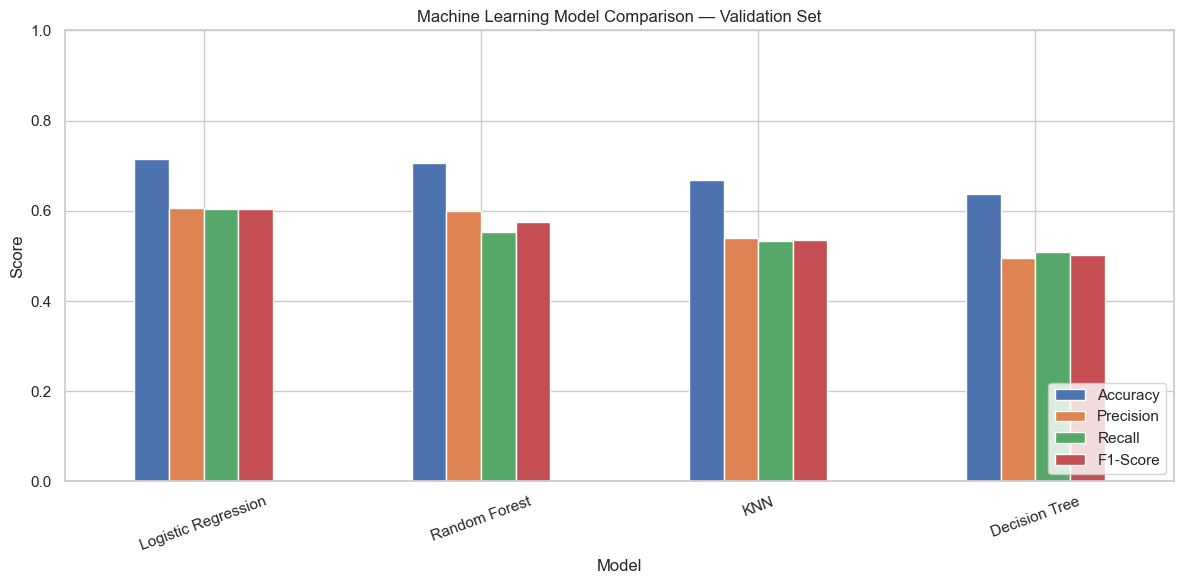

In [44]:
validation_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison — Validation Set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [45]:
best_model_name = validation_results.iloc[0]["Model"]

print("Best model based on validation F1-score:")
print(best_model_name)

Best model based on validation F1-score:
Logistic Regression


In [46]:
best_model = models[best_model_name]

best_model.fit(X_train_processed, y_train)

print("Selected model retrained on all training data.")

Selected model retrained on all training data.


In [47]:
y_test_pred = best_model.predict(X_test_processed)

print("Final Test Results")
print("-" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_test_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_test_pred, zero_division=0), 4))

print("F1-Score:",
      round(f1_score(y_test, y_test_pred, zero_division=0), 4))

Final Test Results
----------------------------------------
Accuracy: 0.736
Precision: 0.6421
Recall: 0.6047
F1-Score: 0.6229


In [48]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Non-Viral", "Viral"],
    zero_division=0
))

              precision    recall  f1-score   support

   Non-Viral       0.78      0.81      0.80      1279
       Viral       0.64      0.60      0.62       721

    accuracy                           0.74      2000
   macro avg       0.71      0.71      0.71      2000
weighted avg       0.73      0.74      0.73      2000



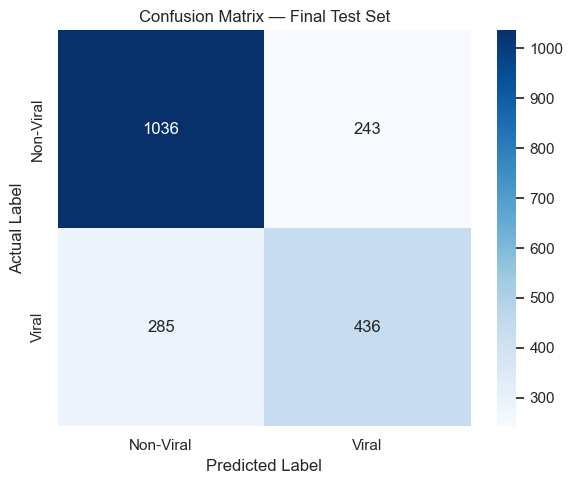

In [49]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Viral", "Viral"],
    yticklabels=["Non-Viral", "Viral"]
)

plt.title("Confusion Matrix — Final Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()